In [1]:
library(CellChat)
library(reticulate)
library(Matrix)

Loading required package: dplyr


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: igraph


Attaching package: ‘igraph’


The following objects are masked from ‘package:dplyr’:

    as_data_frame, groups, union


The following objects are masked from ‘package:stats’:

    decompose, spectrum


The following object is masked from ‘package:base’:

    union


Loading required package: ggplot2



In [2]:
ad <- import('anndata')

In [3]:
adata <- ad$read_h5ad("./data/scncc_sub_anno.h5ad")

In [4]:
sparse_matrix <- Matrix(adata$layers[["counts"]], sparse = TRUE)

counts <- t(sparse_matrix)

library.size <- Matrix::colSums(counts)
data.input <- as(log1p(Matrix::t(Matrix::t(counts)/library.size) * 10000), "dgCMatrix")

meta <- adata$obs
meta$celltype <- meta$anno_II

In [5]:
colnames(data.input) <- rownames(meta)
rownames(data.input) <- rownames(adata$var)

In [6]:
non_cancer_idx <- which(meta$group == "Normal")
cancer_idx <- which(meta$group == "Cancer")

normal_data <- data.input[, non_cancer_idx]
cancer_data <- data.input[, cancer_idx]

normal_meta <- meta[non_cancer_idx, , drop = FALSE]
cancer_meta <- meta[cancer_idx, , drop = FALSE]

In [7]:
cc_normal <- createCellChat(object = normal_data, meta = normal_meta, group.by = "celltype")
cc_cancer <- createCellChat(object = cancer_data, meta = cancer_meta, group.by = "celltype")

[1] "Create a CellChat object from a data matrix"
Set cell identities for the new CellChat object 
The cell groups used for CellChat analysis are  CD4+ Tem CD4+ Tex CD8+ Tex Epi_1 Epi_2 Epi_3 NK cell ecm_CAF i_CAF myo_CAF pro_Fibro sc_Fibro 
[1] "Create a CellChat object from a data matrix"
Set cell identities for the new CellChat object 
The cell groups used for CellChat analysis are  CD4+ Tem CD4+ Tex CD8+ Tex Epi_1 Epi_2 Epi_3 NK cell ecm_CAF i_CAF myo_CAF pro_Fibro sc_Fibro 


In [8]:
cc_normal <- setIdent(cc_normal, ident.use = "celltype")
cc_normal@idents <- droplevels(cc_normal@idents)
length(levels(cc_normal@idents))

[1] 12

In [9]:
groupSize <- as.numeric(table(cc_normal@idents))
CellChatDB <- CellChatDB.human # use CellChatDB.mouse if running on mouse data
CellChatDB.use <- subsetDB(CellChatDB, search = "Secreted Signaling", key = "annotation") # use Secreted Signaling
cc_normal@DB <- CellChatDB.use

In [10]:
cc_normal <- subsetData(cc_normal)
future::plan("multisession", workers = 32)
cc_normal <- identifyOverExpressedGenes(cc_normal)
cc_normal <- identifyOverExpressedInteractions(cc_normal)
cc_normal <- computeCommunProb(cc_normal, type = "triMean")

triMean is used for calculating the average gene expression per cell group. 
[1] ">>> Run CellChat on sc/snRNA-seq data <<< [2025-12-13 17:06:54]"
[1] ">>> CellChat inference is done. Parameter values are stored in `object@options$parameter` <<< [2025-12-13 17:32:26]"


In [ ]:
cc_normal <- filterCommunication(cc_normal, min.cells = 10)
cc_normal <- computeCommunProbPathway(cc_normal)
cc_normal <- aggregateNet(cc_normal)

The cell-cell communication related with the following cell groups are excluded due to the few number of cells:  Epi_1 


In [ ]:
group_size_normal <- as.numeric(table(cc_normal@idents))

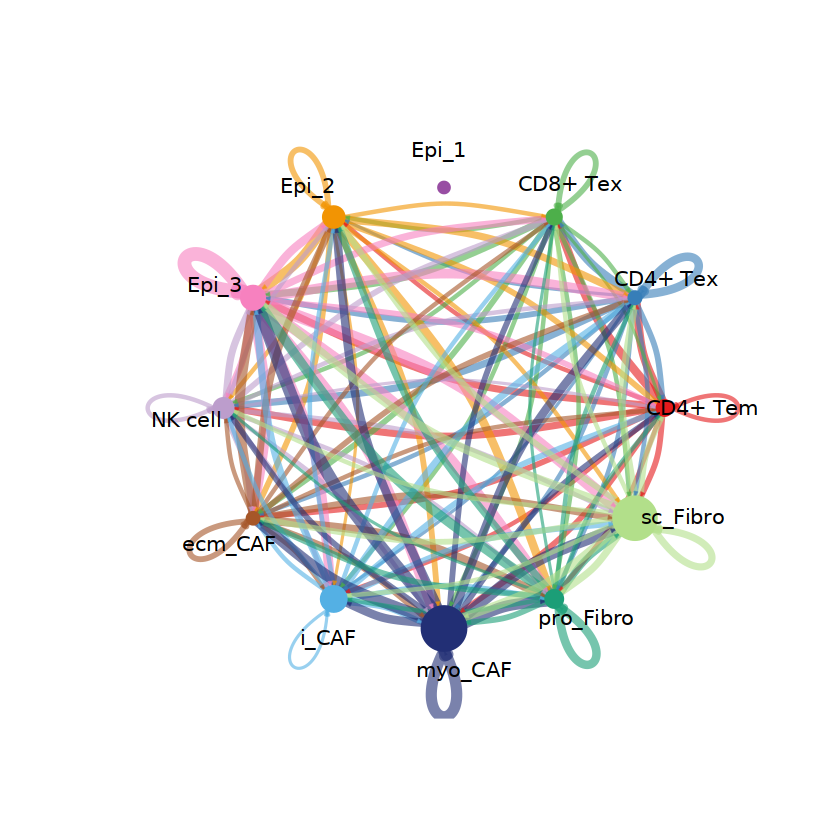

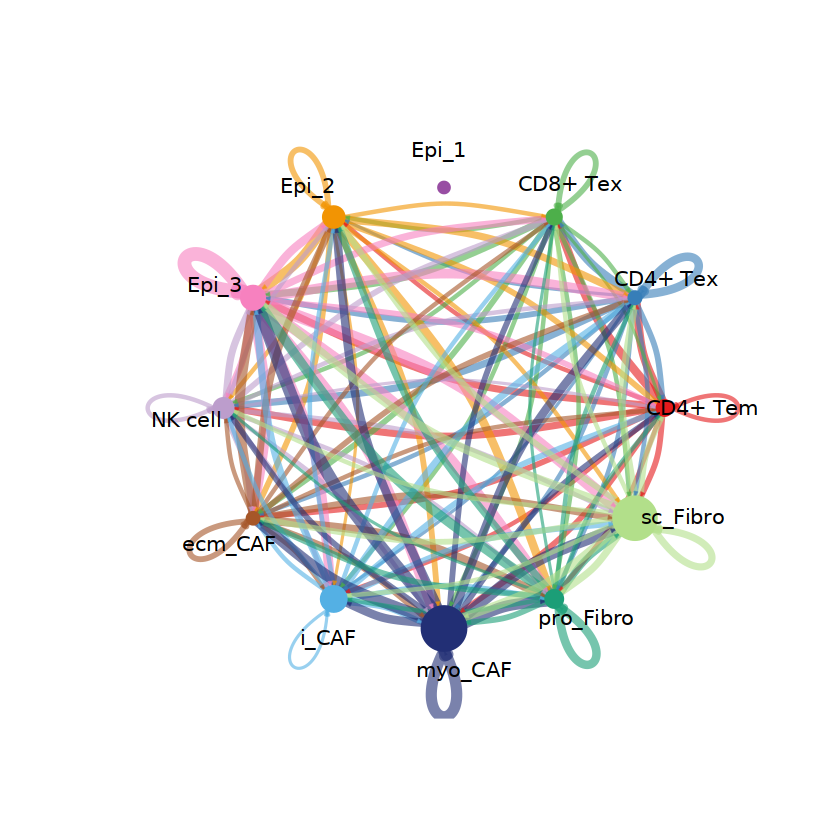

In [ ]:
netVisual_circle(cc_normal@net$count, vertex.weight = group_size_normal, weight.scale = T, label.edge= F)

In [ ]:
pdf("./fig/fig8_normal_network_count.pdf", width = 6, height = 6)
p <- netVisual_circle(cc_normal@net$count, vertex.weight = group_size_normal, weight.scale = T, label.edge= F) # Number of interactions
print(p)
dev.off()

png 
  2

In [15]:
cc_cancer <- setIdent(cc_cancer, ident.use = "celltype")
cc_cancer@idents <- droplevels(cc_cancer@idents)
length(levels(cc_cancer@idents))

groupSize <- as.numeric(table(cc_cancer@idents))
CellChatDB <- CellChatDB.human # use CellChatDB.mouse if running on mouse data
CellChatDB.use <- subsetDB(CellChatDB, search = "Secreted Signaling", key = "annotation") # use Secreted Signaling
cc_cancer@DB <- CellChatDB.use

cc_cancer <- subsetData(cc_cancer)
future::plan("multisession", workers = 32)
cc_cancer <- identifyOverExpressedGenes(cc_cancer)
cc_cancer <- identifyOverExpressedInteractions(cc_cancer)
cc_cancer <- computeCommunProb(cc_cancer, type = "triMean")

cc_cancer <- filterCommunication(cc_cancer, min.cells = 10)
cc_cancer <- computeCommunProbPathway(cc_cancer)
cc_cancer <- aggregateNet(cc_cancer)

[1] 12

triMean is used for calculating the average gene expression per cell group. 
[1] ">>> Run CellChat on sc/snRNA-seq data <<< [2025-12-13 17:38:58]"
[1] ">>> CellChat inference is done. Parameter values are stored in `object@options$parameter` <<< [2025-12-13 17:44:21]"


In [ ]:
print('end')

[1] "end"


In [ ]:
group_size_cancer <- as.numeric(table(cc_cancer@idents))

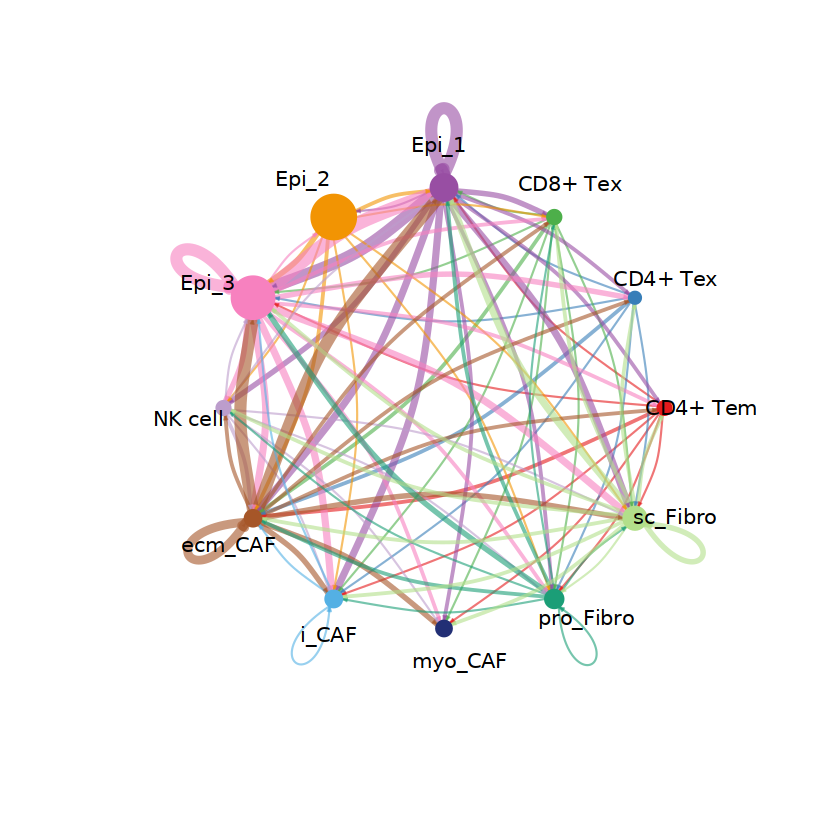

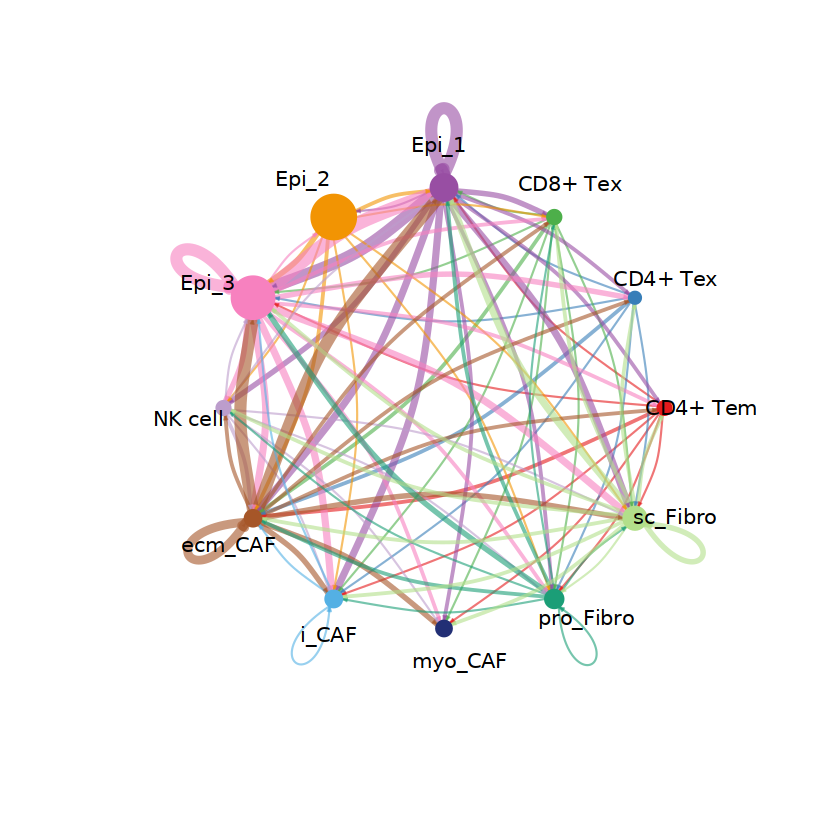

In [ ]:
netVisual_circle(cc_cancer@net$count, vertex.weight = group_size_cancer, weight.scale = T, label.edge= F)

In [ ]:
pdf("./fig/fig8_cancer_network_count.pdf", width = 6, height = 6)
p <- netVisual_circle(cc_cancer@net$count, vertex.weight = group_size_cancer, weight.scale = T, label.edge= F) # Number of interactions
print(p)
dev.off()

png 
  2

In [ ]:
cc_merge <- mergeCellChat(list(Cancer = cc_cancer, Normal = cc_normal), add.names = c("Cancer", "Normal"))

Merge the following slots: 'data.signaling','images','net', 'netP','meta', 'idents', 'var.features' , 'DB', and 'LR'.



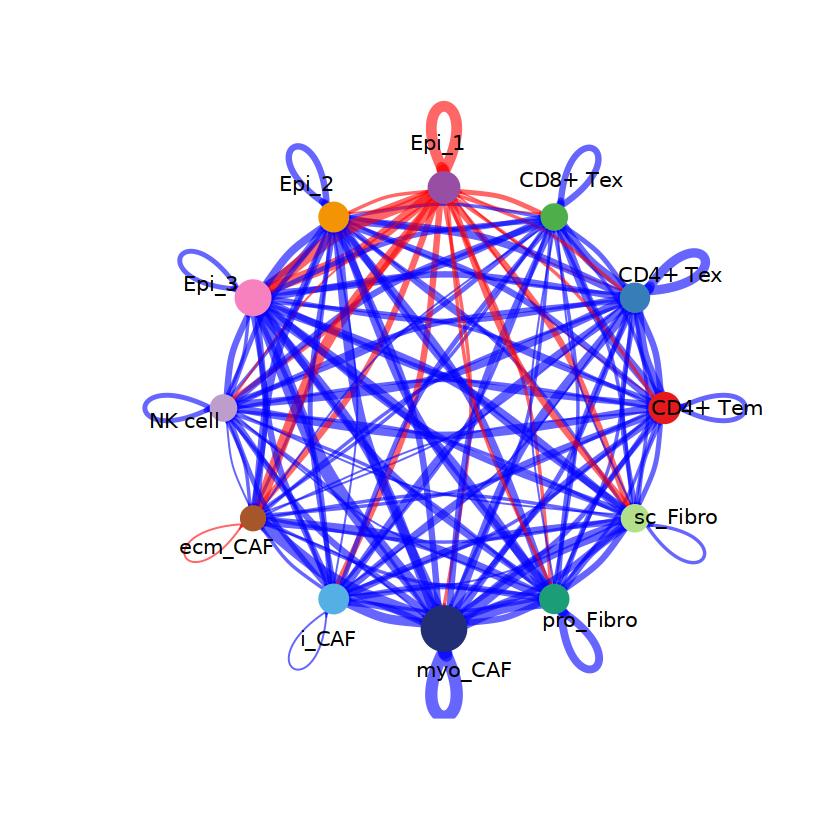

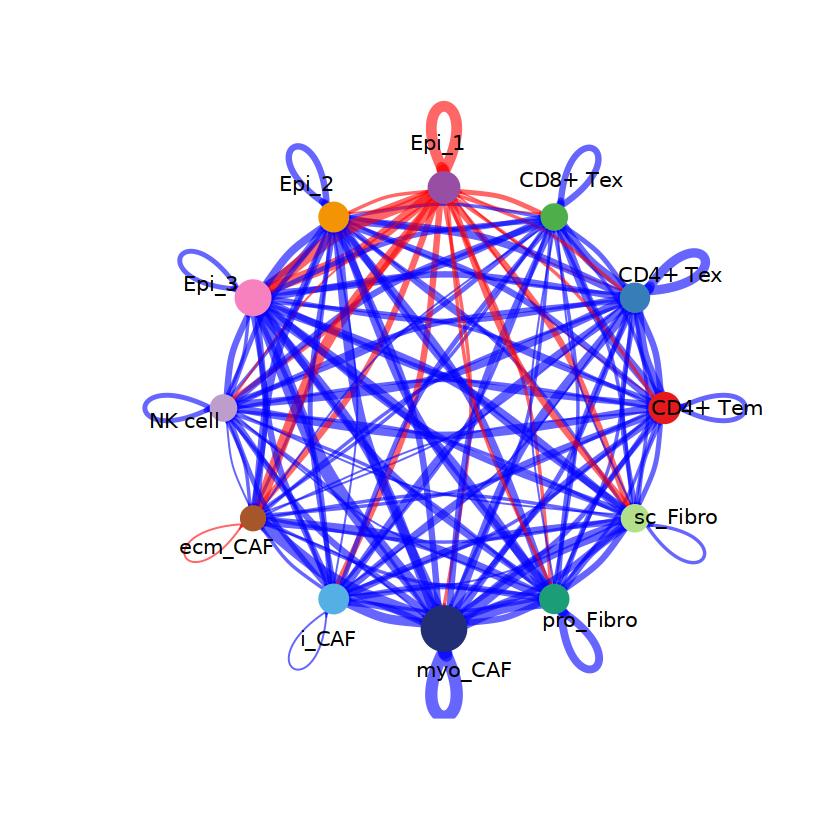

In [22]:
df_c_normal <- cc_merge@net$Normal$count
df_c_cancer <- cc_merge@net$Cancer$count
diff_count   <- df_c_cancer - df_c_normal

vertex.w <- rowSums(abs(diff_count))

netVisual_diffInteraction(
  object        = cc_merge,
  comparison    = c("Normal", "Cancer"),
  measure       = "count",
  color.edge    = c("red", "blue"),    # 正值边=红色，负值边=蓝色
  vertex.weight = vertex.w,
  weight.scale  = TRUE,
  vertex.label.cex = 1,
  arrow.size    = 0.1,
  title.name    = "Cancer − Normal (#interactions)"
)

In [23]:
pdf("./fig/fig8_diff_network_count.pdf", width = 6, height = 6)
p <- netVisual_diffInteraction(
  object        = cc_merge,
  comparison    = c("Normal", "Cancer"),
  measure       = "count",
  color.edge    = c("red", "blue"),    # 正值边=红色，负值边=蓝色
  vertex.weight = vertex.w,
  weight.scale  = TRUE,
  vertex.label.cex = 1,
  arrow.size    = 0.1,
  title.name    = "Cancer − Normal (#interactions)"
)
print(p)
dev.off()

png 
  2

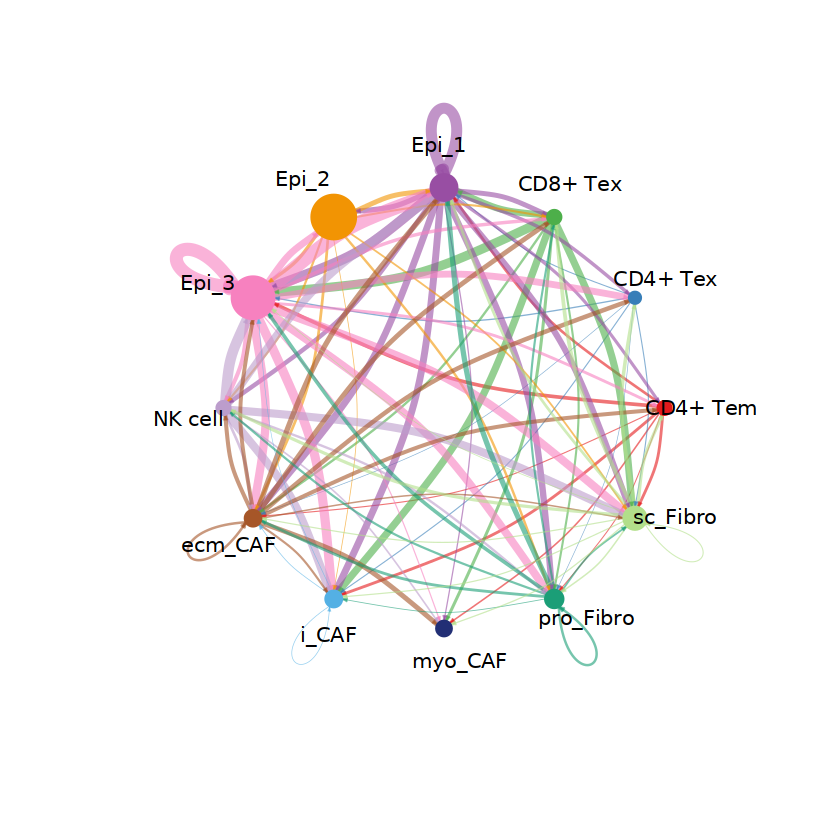

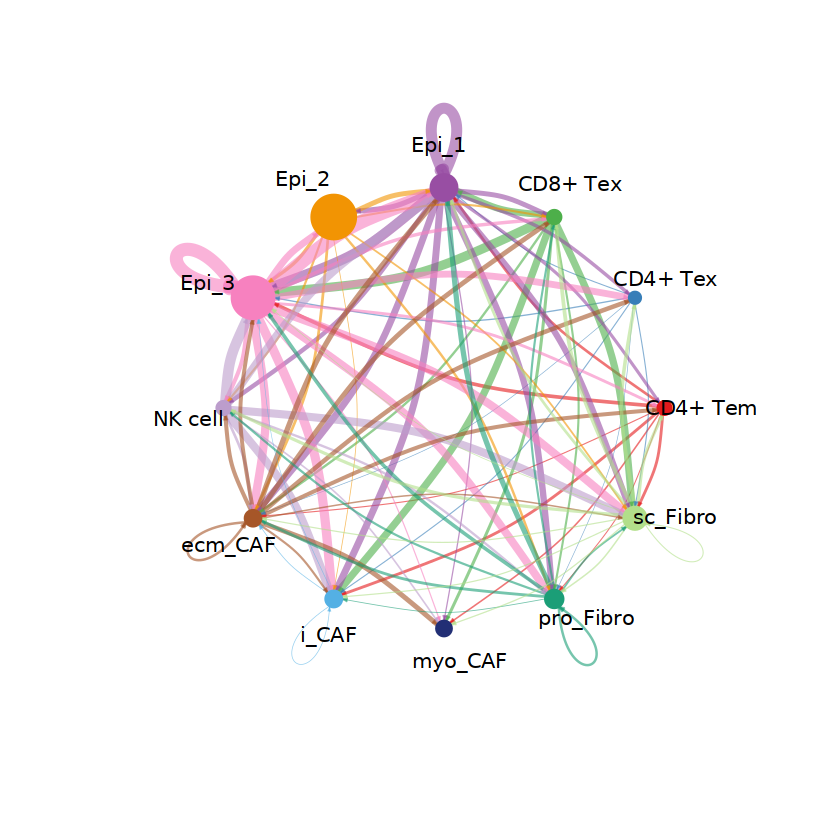

In [24]:
netVisual_circle(cc_cancer@net$weight, vertex.weight = group_size_cancer, weight.scale = T, label.edge= F) # Interaction strength

In [25]:
pdf("./fig/fig8_cancer_network_weight.pdf", width = 6, height = 6)
p <- netVisual_circle(cc_cancer@net$weight, vertex.weight = group_size_cancer, weight.scale = T, label.edge= F) # Interaction strength
print(p)
dev.off()

png 
  2

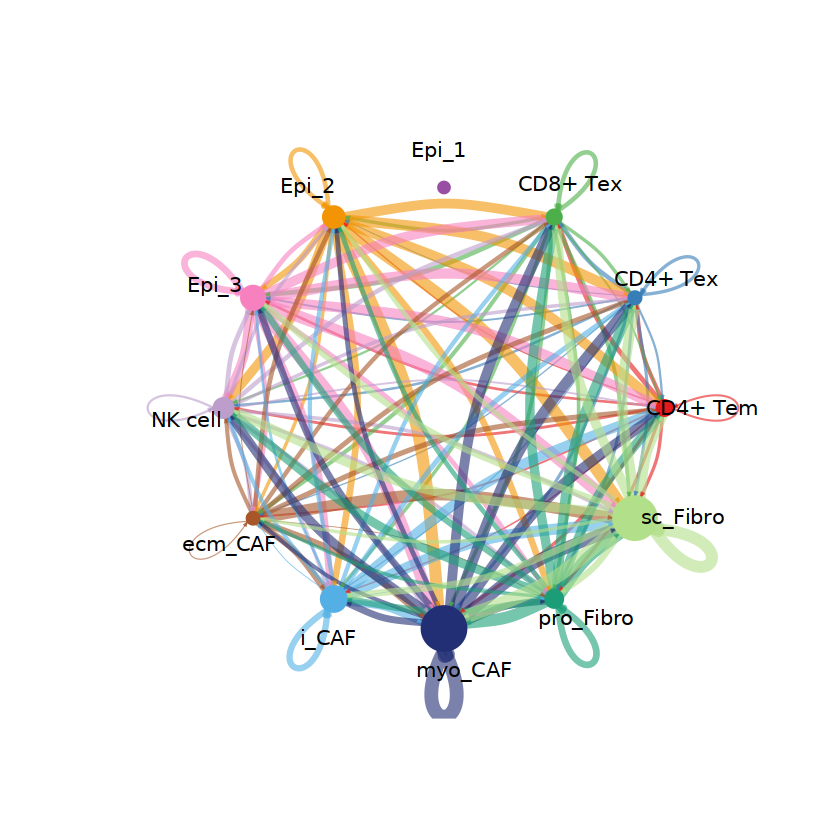

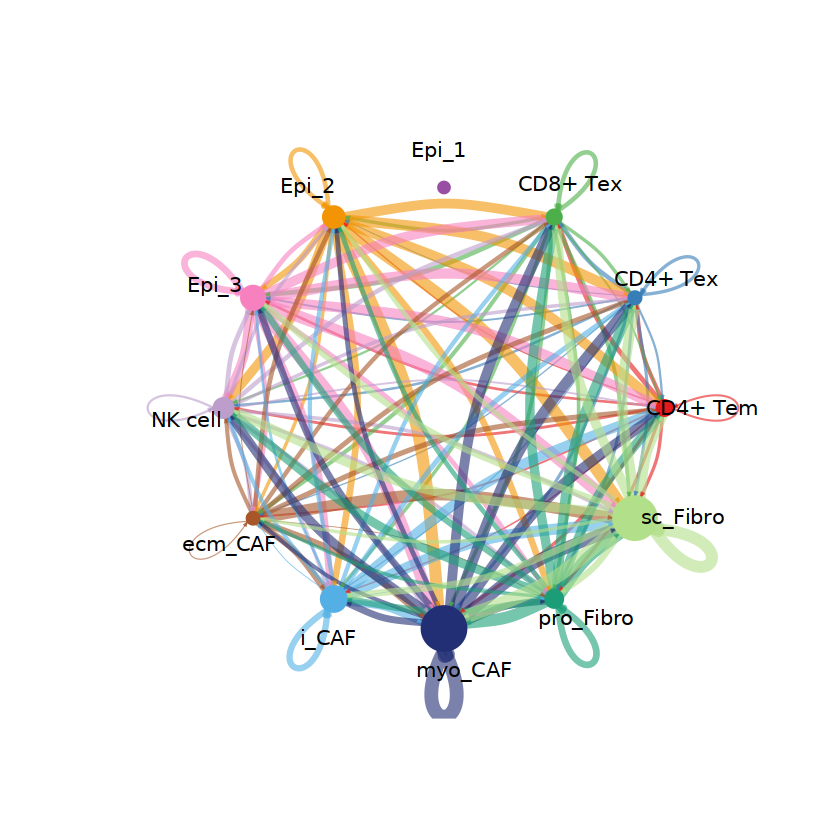

In [26]:
netVisual_circle(cc_normal@net$weight, vertex.weight = group_size_normal, weight.scale = T, label.edge= F) # Interaction strength

In [27]:
pdf("./fig/fig8_normal_network_weight.pdf", width = 6, height = 6)
p <- netVisual_circle(cc_normal@net$weight, vertex.weight = group_size_normal, weight.scale = T, label.edge= F) # Interaction strength
print(p)
dev.off()

png 
  2

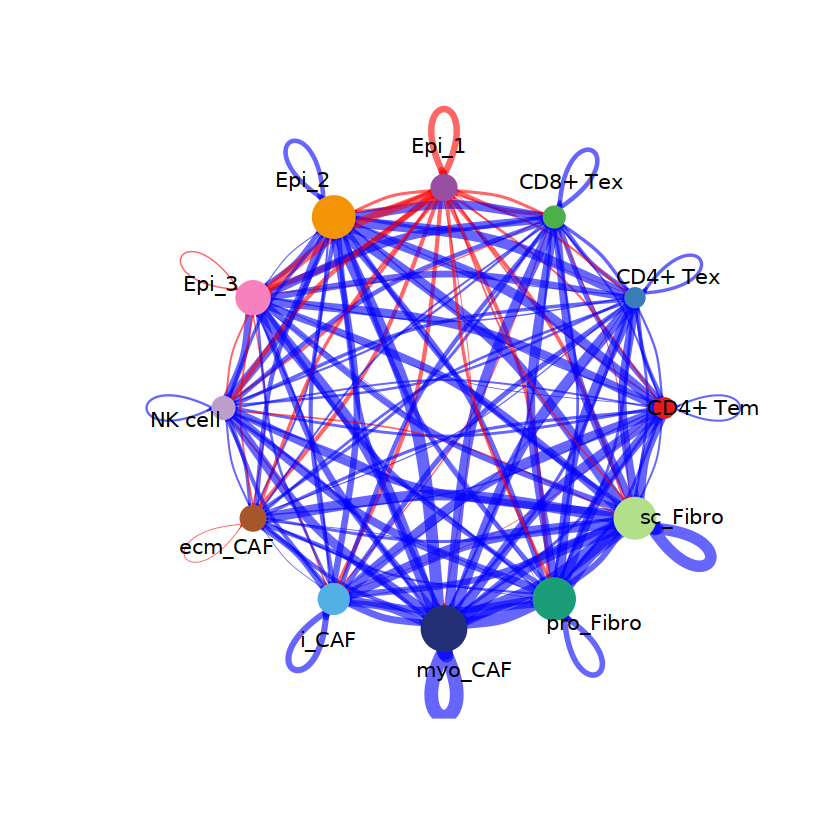

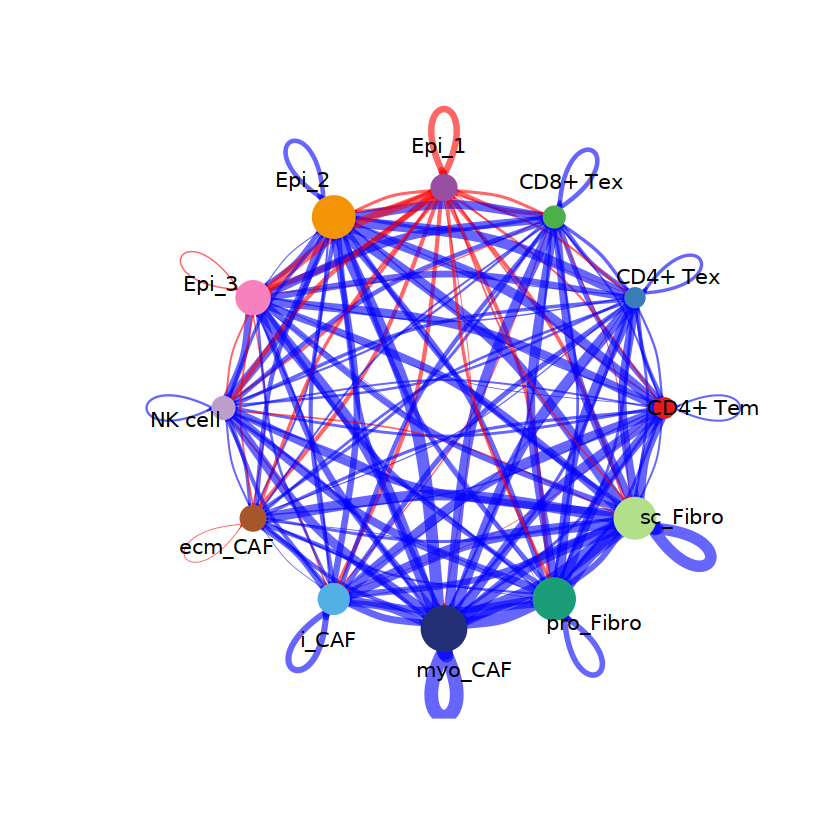

In [28]:
df_w_normal <- cc_merge@net$Normal$weight
df_w_cancer <- cc_merge@net$Cancer$weight
diff_weight   <- df_w_cancer - df_w_normal

vertex.w <- rowSums(abs(diff_weight))

netVisual_diffInteraction(
  object        = cc_merge,
  comparison    = c("Normal", "Cancer"),
  measure       = "weight",
  color.edge    = c("red", "blue"),    # 正值边=红色，负值边=蓝色
  vertex.weight = vertex.w,
  weight.scale  = TRUE,
  vertex.label.cex = 1,
  arrow.size    = 0.1,
  title.name    = "Cancer − Normal (#interactions)"
)

In [29]:
pdf("./fig/fig8_diff_network_weight.pdf", width = 6, height = 6)
p <- netVisual_diffInteraction(
  object        = cc_merge,
  comparison    = c("Normal", "Cancer"),
  measure       = "weight",
  color.edge    = c("red", "blue"),    # 正值边=红色，负值边=蓝色
  vertex.weight = vertex.w,
  weight.scale  = TRUE,
  vertex.label.cex = 1,
  arrow.size    = 0.1,
  title.name    = "Cancer − Normal (#interactions)"
)
print(p)
dev.off()

png 
  2

In [30]:
pdf("./fig/fig8_count_diff_heatmap.pdf", width = 6, height = 6)

p <- netVisual_heatmap(
  object      = cc_merge,
  comparison  = c("Cancer", "Normal"),         # 1=Normal, 2=Cancer；顺序一定要和你 merge 时一致
  measure     = "count",         # 差异的交互数目
  color.heatmap = c("#2166ac", "#b2182b"),  # 蓝=减少，红=增加
  title.name  = "Differential number of interactions",
  cluster.rows = FALSE,
  cluster.cols = FALSE
)

print(p)
dev.off()

Do heatmap based on a merged object 




png 
  2

In [31]:
pdf("./fig/fig8_weight_diff_heatmap.pdf", width = 6, height = 6)

p <- netVisual_heatmap(
  object      = cc_merge,
  comparison  = c("Cancer", "Normal"),
  measure     = "weight",        # 差异的总交互强度
  color.heatmap = c("#2166ac", "#b2182b"),
  title.name  = "Differential interaction strength",
  cluster.rows = FALSE,
  cluster.cols = FALSE
)

print(p)
dev.off()

Do heatmap based on a merged object 




png 
  2

In [32]:
cc_normal <- netAnalysis_computeCentrality(cc_normal, slot.name = "netP")
cc_cancer <- netAnalysis_computeCentrality(cc_cancer, slot.name = "netP")

In [ ]:
cc_merge_heatmap <- mergeCellChat(list(Normal = cc_normal, Tumor  = cc_cancer), add.names = c("Normal", "Tumor"))

Merge the following slots: 'data.signaling','images','net', 'netP','meta', 'idents', 'var.features' , 'DB', and 'LR'.



In [ ]:
pdf("./fig/fig8_diff_pathway_heatmap.pdf", width = 4, height = 6)

p <- rankNet(
  object     = cc_merge_heatmap,
  mode       = "comparison",
  stacked    = TRUE,          # 关键：堆叠条形图 = 你图里的 I
  do.stat    = FALSE,         # 要不要显著性检验，按需
  #color.use  = cols.cond,
  # pathways.show = NULL      # 想只画部分通路可以指定一个向量
)

print(p)
dev.off()

png 
  2

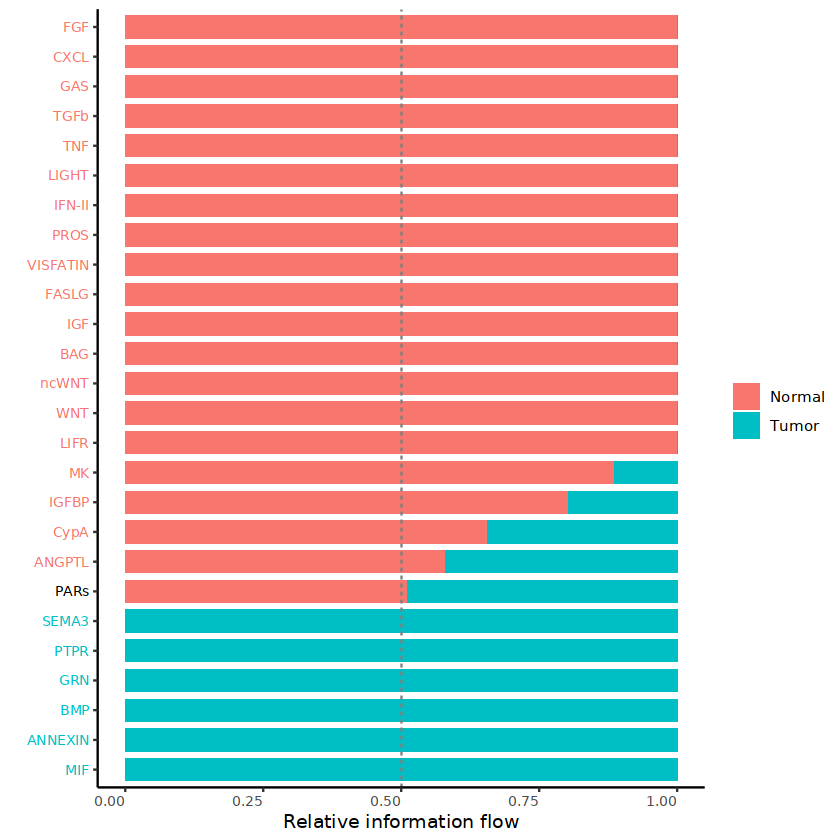

In [ ]:
rankNet(
  object     = cc_merge_heatmap,
  mode       = "comparison",
  stacked    = TRUE,          # 关键：堆叠条形图 = 你图里的 I
  do.stat    = FALSE,         # 要不要显著性检验，按需
  #color.use  = cols.cond,
  # pathways.show = NULL      # 想只画部分通路可以指定一个向量
)

In [ ]:
pdf("./fig/fig8_diff_pathway_stack.pdf", width = 4, height = 6)

p <- rankNet(
  object     = cc_merge_heatmap,
  mode       = "comparison",
  stacked    = FALSE,         # 关键：并列条形图 = 你图里的 J
  do.stat    = FALSE,
  #color.use  = cols.cond
)

print(p)
dev.off()

png 
  2

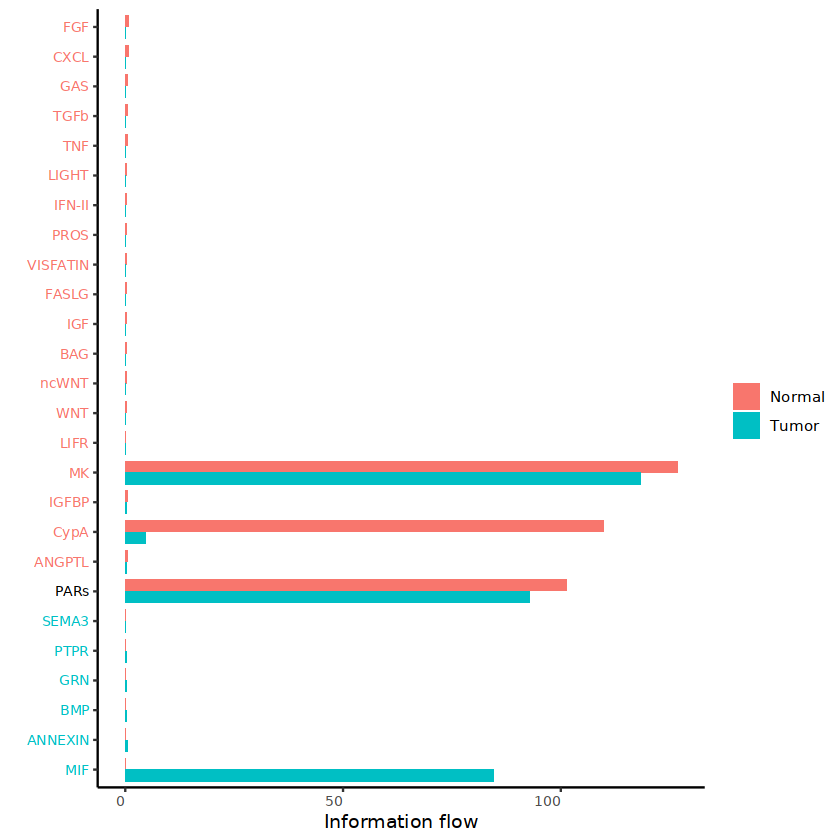

In [38]:
rankNet(
  object     = cc_merge_heatmap,
  mode       = "comparison",
  stacked    = FALSE,         # 关键：并列条形图 = 你图里的 J
  do.stat    = FALSE,
  #color.use  = cols.cond
)

In [39]:
pathway_show <- c('CypA')

pdf("./fig/fig8_pathway_1_network_normal_CypA.pdf", width = 6, height = 6)
p <- netVisual_aggregate(cc_normal, signaling = pathway_show,  vertex.receiver = vertex.receiver)
print(p)
dev.off()

png 
  2

In [40]:
pathway_show <- c('CypA')

pdf("./fig/fig8_pathway_1_network_cancer_CypA.pdf", width = 6, height = 6)
p <- netVisual_aggregate(cc_cancer, signaling = pathway_show,  vertex.receiver = vertex.receiver)
print(p)
dev.off()

png 
  2

In [43]:
pathway_show <- c('MK')

pdf("./fig/fig8_pathway_2_network_normal_NK.pdf", width = 6, height = 6)
p <- netVisual_aggregate(cc_normal, signaling = pathway_show,  vertex.receiver = vertex.receiver)
print(p)
dev.off()

png 
  2

In [44]:
pathway_show <- c('MK')

pdf("./fig/fig8_pathway_2_network_cancer_MK.pdf", width = 6, height = 6)
p <- netVisual_aggregate(cc_cancer, signaling = pathway_show,  vertex.receiver = vertex.receiver)
print(p)
dev.off()

png 
  2

In [48]:
pdf("./fig/fig8_pathway_MK_violin.pdf", width = 6, height = 8)

p <- plotGeneExpression(
  object        = cc_merge,
  signaling     = "MK",   # 这里换成你的通路名
  enriched.only = TRUE,          # 只画显著的配受体相关基因
  type          = "violin",
  split.by      = "datasets",    # 一列里 Normal/Tumor 两个小提琴
  # color.use     = cols.cond
)

print(p)
dev.off()

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


png 
  2

In [47]:
pdf("./fig/fig8_pathway_CypA_violin.pdf", width = 6, height = 8)

p <- plotGeneExpression(
  object        = cc_merge,
  signaling     = "CypA",   # 这里换成你的通路名
  enriched.only = TRUE,          # 只画显著的配受体相关基因
  type          = "violin",
  split.by      = "datasets",    # 一列里 Normal/Tumor 两个小提琴
  # color.use     = cols.cond
)

print(p)
dev.off()

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


png 
  2